In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 0

In [2]:
train_raw = pd.read_csv("data/train_2020_2024.csv", parse_dates=["date"])
test_raw = pd.read_csv("data/test_2025.csv", parse_dates=["date"])
print(len(train_raw), "training rows,", len(test_raw), "test rows")
train_raw.head()

3654 training rows, 730 test rows


,station,date,pm25,temperature_2m,relative_humidity_2m,precipitation,surface_pressure,wind_speed_10m,wind_u,wind_v,rain_prev_day
0,Jakarta Central,2020-01-01,19.0,25.687500,92.375000,94.0,1010.908333,7.208333,6.261814,0.725178,NaN
1,Jakarta Central,2020-01-02,24.7,26.608333,84.500000,12.6,1011.304167,9.200000,7.677201,-0.767226,94.0
2,Jakarta Central,2020-01-03,27.3,27.175000,83.500000,10.5,1009.504167,12.504167,11.465163,-2.821384,12.6
3,Jakarta Central,2020-01-04,23.1,26.470833,86.791667,14.7,1008.137500,11.670833,10.885557,-2.499538,10.5
4,Jakarta Central,2020-01-05,28.0,25.979167,89.291667,15.2,1008.366667,12.675000,11.662837,-2.386880,14.7


In [3]:
both = pd.concat([train_raw, test_raw])
both.groupby([both["date"].dt.year, "station"])["pm25"].count().unstack()

station,Jakarta Central,Jakarta South
date,,
2020,325,321
2021,350,353
2022,337,329
2023,329,235
2024,338,312
2025,99,289


In [4]:
both.groupby(both["date"].dt.year)["pm25"].mean().round(1)

date
2020    37.5
2021    34.9
2022    30.8
2023    36.3
2024    34.4
2025    29.0
Name: pm25, dtype: float64

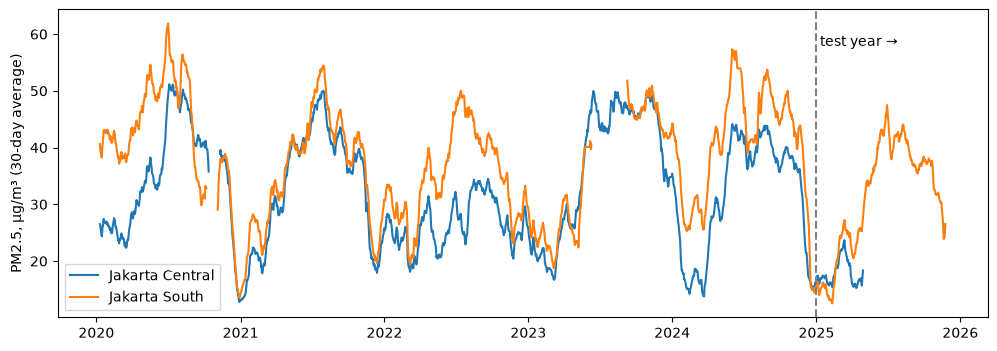

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
for name, g in both.groupby("station"):
    ax.plot(g["date"], g["pm25"].rolling(30, min_periods=10).mean(), label=name)
ax.axvline(pd.Timestamp("2025-01-01"), color="grey", ls="--")
ax.text(pd.Timestamp("2025-01-10"), ax.get_ylim()[1] * 0.9, "test year →")
ax.set_ylabel("PM2.5, µg/m³ (30-day average)")
ax.legend()
plt.show()

In [6]:
CATEGORY_TOPS = [9.0, 35.4, 55.4, 125.4, 225.4]
CATEGORY_NAMES = ["Good", "Moderate", "Unhealthy (sensitive)", "Unhealthy", "Very unhealthy", "Hazardous"]

def category(pm25):
    pm25 = np.floor(np.asarray(pm25, dtype=float) * 10) / 10
    return np.digitize(pm25, CATEGORY_TOPS, right=True)

category([5, 9.0, 20, 40, 80])

array([0, 0, 1, 2, 3])

In [7]:
df = pd.concat([train_raw, test_raw]).sort_values(["station", "date"]).reset_index(drop=True)

df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
angle = 2 * np.pi * df["date"].dt.dayofyear / 365.25
df["season_sin"] = np.sin(angle)
df["season_cos"] = np.cos(angle)
df["is_south"] = (df["station"] == "Jakarta South").astype(int)

df["pm_yesterday"] = df.groupby("station")["pm25"].shift(1)
df["pm_2days_ago"] = df.groupby("station")["pm25"].shift(2)

WEATHER = ["temperature_2m", "relative_humidity_2m", "precipitation", "rain_prev_day",
           "surface_pressure", "wind_speed_10m", "wind_u", "wind_v"]
CALENDAR = ["day_of_week", "season_sin", "season_cos", "is_south"]

FEATURES_A = WEATHER + CALENDAR
FEATURES_B = WEATHER + CALENDAR + ["pm_yesterday", "pm_2days_ago"]
df[FEATURES_B + ["pm25"]].describe().round(1)

,temperature_2m,relative_humidity_2m,precipitation,rain_prev_day,surface_pressure,wind_speed_10m,wind_u,wind_v,day_of_week,season_sin,season_cos,is_south,pm_yesterday,pm_2days_ago,pm25
count,4384.0,4384.0,4384.0,4382.0,4384.0,4384.0,4384.0,4384.0,4384.0,4384.0,4384.0,4384.0,3617.0,3617.0,3617.0
mean,27.0,81.7,6.7,6.7,1008.1,6.7,1.5,-0.1,3.0,0.0,0.0,0.5,34.1,34.1,34.1
std,0.9,6.1,8.3,8.2,1.4,2.4,4.7,1.8,2.0,0.7,0.7,0.5,14.8,14.8,14.8
min,23.8,52.5,0.0,0.0,1003.8,2.2,-14.1,-8.0,0.0,-1.0,-1.0,0.0,2.6,2.6,2.6
25%,26.5,78.5,1.1,1.1,1007.1,5.0,-1.6,-1.2,1.0,-0.7,-0.7,0.0,22.4,22.4,22.4
50%,27.1,82.9,4.0,4.0,1008.1,6.1,0.3,-0.1,3.0,-0.0,0.0,0.5,34.0,34.0,34.0
75%,27.6,86.2,9.7,9.6,1009.1,7.7,4.0,0.9,5.0,0.7,0.7,1.0,44.2,44.2,44.2
max,30.3,94.6,150.4,150.4,1012.6,19.0,18.0,8.1,6.0,1.0,1.0,1.0,90.1,90.1,90.1


In [8]:
def score(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "R2": r2_score(actual, predicted),
        "AQI category correct": (category(actual) == category(predicted)).mean(),
    }

In [9]:
MODELS = {
    "Ridge (linear)": (make_pipeline(StandardScaler(), Ridge()),
                       {"ridge__alpha": [0.1, 1, 10, 100]}),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
                      {"max_depth": [4, 8, None], "min_samples_leaf": [1, 5, 20]}),
    "LightGBM": (lgb.LGBMRegressor(n_estimators=300, random_state=SEED, verbose=-1),
                 {"learning_rate": [0.03, 0.1], "num_leaves": [7, 15, 31], "min_child_samples": [10, 30]}),
}

In [10]:
def run_task(features, use_persistence):
    d = df.dropna(subset=["pm25"] + features)
    train = d[d["date"].dt.year <= 2024]
    test = d[d["date"].dt.year == 2025]
    print(f"{len(train)} training days, {len(test)} test days")

    predictions = pd.DataFrame({"station": test["station"], "date": test["date"], "actual": test["pm25"]})

    monthly_avg = train.groupby(["station", "month"])["pm25"].mean()
    predictions["Climatology (baseline)"] = [monthly_avg[s, m] for s, m in zip(test["station"], test["month"])]

    if use_persistence:
        predictions["Persistence (baseline)"] = test["pm_yesterday"]

    for name, (model, settings) in MODELS.items():
        search = GridSearchCV(model, settings, cv=TimeSeriesSplit(n_splits=4),
                              scoring="neg_mean_absolute_error", n_jobs=-1)
        train_sorted = train.sort_values(["date", "station"])
        search.fit(train_sorted[features], train_sorted["pm25"])
        predictions[name] = search.best_estimator_.predict(test[features])
        print(f"  {name}: best settings {search.best_params_}")
        MODELS_FITTED[name] = search.best_estimator_

    results = pd.DataFrame({name: score(predictions["actual"], predictions[name])
                            for name in predictions.columns[3:]}).T
    return results.sort_values("MAE"), predictions

MODELS_FITTED = {}

In [11]:
results_a, preds_a = run_task(FEATURES_A, use_persistence=False)
models_a = dict(MODELS_FITTED)
results_a.round(3)

3227 training days, 388 test days


  Ridge (linear): best settings {'ridge__alpha': 100}


  Random Forest: best settings {'max_depth': None, 'min_samples_leaf': 20}


  LightGBM: best settings {'learning_rate': 0.03, 'min_child_samples': 30, 'num_leaves': 7}


,MAE,RMSE,R2,AQI category correct
LightGBM,9.976,12.073,0.228,0.626
Climatology (baseline),9.988,12.397,0.186,0.673
Random Forest,10.119,12.053,0.231,0.611
Ridge (linear),11.035,12.917,0.117,0.595


In [12]:
results_b, preds_b = run_task(FEATURES_B, use_persistence=True)
results_b.round(3)

3129 training days, 376 test days
  Ridge (linear): best settings {'ridge__alpha': 100}


  Random Forest: best settings {'max_depth': 8, 'min_samples_leaf': 5}


  LightGBM: best settings {'learning_rate': 0.03, 'min_child_samples': 30, 'num_leaves': 7}


,MAE,RMSE,R2,AQI category correct
Random Forest,7.107,8.932,0.581,0.689
LightGBM,7.240,8.964,0.578,0.726
Persistence (baseline),7.622,10.112,0.463,0.699
Ridge (linear),7.819,9.546,0.521,0.699
Climatology (baseline),9.989,12.433,0.188,0.668


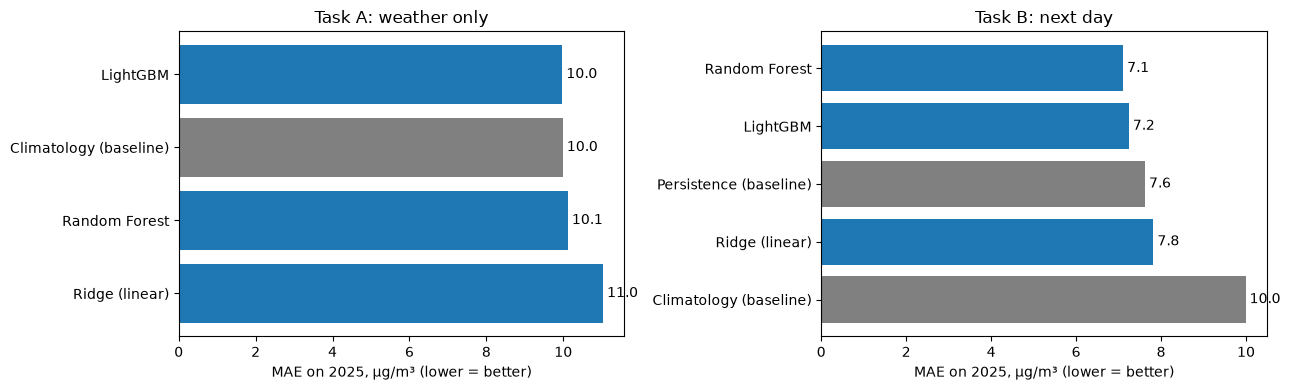

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (title, res) in zip(axes, [("Task A: weather only", results_a), ("Task B: next day", results_b)]):
    res = res.sort_values("MAE", ascending=False)
    colors = ["grey" if "baseline" in n else "tab:blue" for n in res.index]
    ax.barh(res.index, res["MAE"], color=colors)
    for y, v in enumerate(res["MAE"]):
        ax.text(v, y, f" {v:.1f}", va="center")
    ax.set_title(title)
    ax.set_xlabel("MAE on 2025, µg/m³ (lower = better)")
plt.tight_layout()
plt.show()

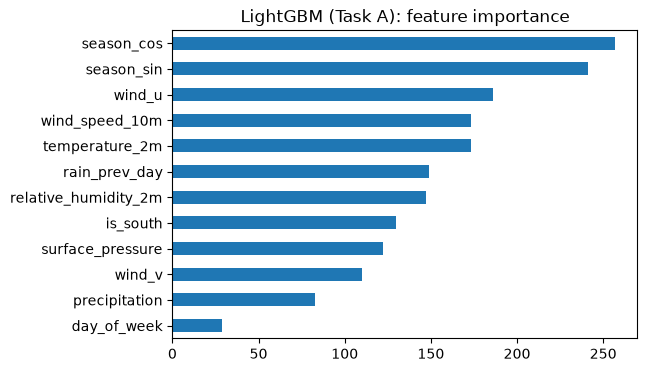

In [14]:
lgbm_a = models_a["LightGBM"]
pd.Series(lgbm_a.feature_importances_, index=FEATURES_A).sort_values().plot.barh(figsize=(6, 4))
plt.title("LightGBM (Task A): feature importance")
plt.show()

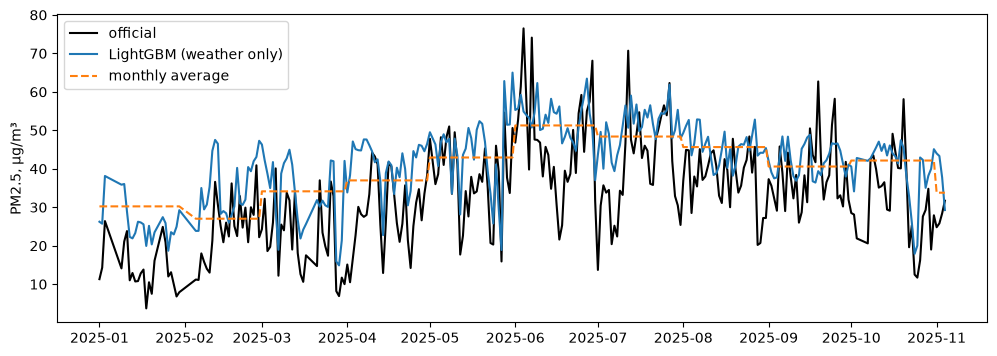

Average official 2025: 32.7
Average LightGBM prediction: 41.7


In [15]:
s = preds_a[preds_a["station"] == "Jakarta South"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s["date"], s["actual"], label="official", color="black")
ax.plot(s["date"], s["LightGBM"], label="LightGBM (weather only)")
ax.plot(s["date"], s["Climatology (baseline)"], label="monthly average", ls="--")
ax.set_ylabel("PM2.5, µg/m³")
ax.legend()
plt.show()

print("Average official 2025:", round(s["actual"].mean(), 1))
print("Average LightGBM prediction:", round(s["LightGBM"].mean(), 1))

In [16]:
import sys
sys.path.insert(0, "src")
from make_heatmap import build

STATIONS = {"Jakarta Central": (-6.182536, 106.834235),
            "Jakarta South": (-6.236704, 106.793244)}
heat = test_raw[["station", "date", "pm25"]].copy()
heat["lat"] = heat["station"].map(lambda s: STATIONS[s][0])
heat["lon"] = heat["station"].map(lambda s: STATIONS[s][1])
models = ["Ridge (linear)", "Random Forest", "LightGBM"]
heat = heat.merge(preds_a[["station", "date"] + models], on=["station", "date"], how="left")

fig = build(heat, [("pm25", "Official 2025 (measured)")] + [(m, f"My {m}") for m in models],
            "2025: official vs my 3 models (weather only)")
fig.show(renderer="notebook_connected")

  colour range: AQI 21 to 166
